In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/ml_projects/plant_compressor_daily_operations.csv')

In [ ]:
df = data
df.head()

,Date,Production_Units,Compressor_Run_Hours,Avg_Header_Pressure_Bar,Ambient_Temperature_C,Idle_Minutes,Active_Production_Lines,Shift_Pattern,Maintenance_Flag,Energy_Consumption_kWh
0,2023-01-01,3824,20.44,7.30,24.3,36,3,Continuous,0,2196.2
1,2023-01-02,4151,15.98,7.08,26.0,150,4,Double,0,2027.6
2,2023-01-03,3770,20.57,6.89,26.1,103,3,Continuous,0,2212.5
3,2023-01-04,5017,20.37,6.78,25.7,145,4,Continuous,0,2429.6
4,2023-01-05,534,8.81,6.74,23.6,49,1,Single,0,883.4


In [ ]:
df.tail()

,Date,Production_Units,Compressor_Run_Hours,Avg_Header_Pressure_Bar,Ambient_Temperature_C,Idle_Minutes,Active_Production_Lines,Shift_Pattern,Maintenance_Flag,Energy_Consumption_kWh
895,2025-06-14,3511,21.00,7.27,31.7,73,3,Continuous,0,2192.3
896,2025-06-15,1866,17.04,8.18,31.2,120,2,Double,0,1959.9
897,2025-06-16,2319,13.24,7.22,25.9,41,3,Double,0,1758.0
898,2025-06-17,452,7.27,6.48,31.6,154,1,Single,0,1031.5
899,2025-06-18,3011,16.21,7.03,28.5,105,3,Double,0,1875.9


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(900, 10)

<function matplotlib.pyplot.show(close=None, block=None)>

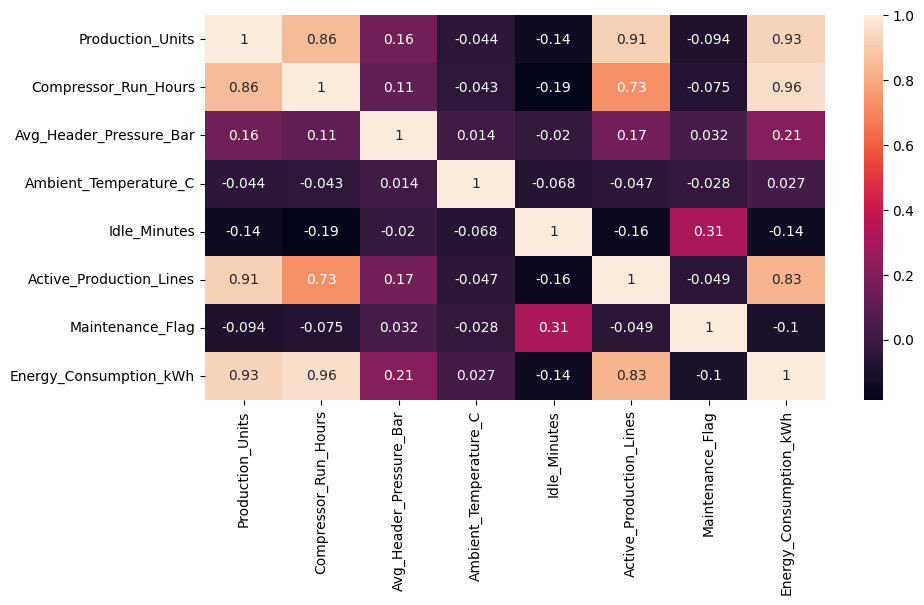

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     900 non-null    object 
 1   Production_Units         900 non-null    int64  
 2   Compressor_Run_Hours     900 non-null    float64
 3   Avg_Header_Pressure_Bar  900 non-null    float64
 4   Ambient_Temperature_C    900 non-null    float64
 5   Idle_Minutes             900 non-null    int64  
 6   Active_Production_Lines  900 non-null    int64  
 7   Shift_Pattern            900 non-null    object 
 8   Maintenance_Flag         900 non-null    int64  
 9   Energy_Consumption_kWh   900 non-null    float64
dtypes: float64(4), int64(4), object(2)
memory usage: 70.4+ KB


In [ ]:
df.drop(columns='Date', inplace=True)

In [ ]:
df.head()

,Production_Units,Compressor_Run_Hours,Avg_Header_Pressure_Bar,Ambient_Temperature_C,Idle_Minutes,Active_Production_Lines,Shift_Pattern,Maintenance_Flag,Energy_Consumption_kWh
0,3824,20.44,7.30,24.3,36,3,Continuous,0,2196.2
1,4151,15.98,7.08,26.0,150,4,Double,0,2027.6
2,3770,20.57,6.89,26.1,103,3,Continuous,0,2212.5
3,5017,20.37,6.78,25.7,145,4,Continuous,0,2429.6
4,534,8.81,6.74,23.6,49,1,Single,0,883.4


In [ ]:
cols = df.columns

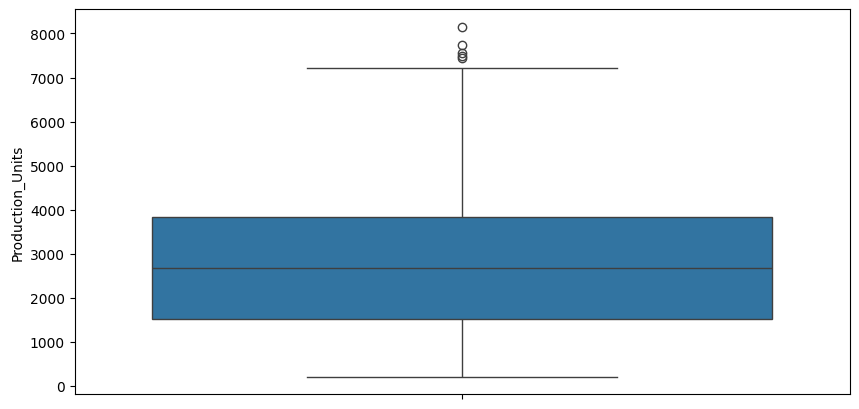

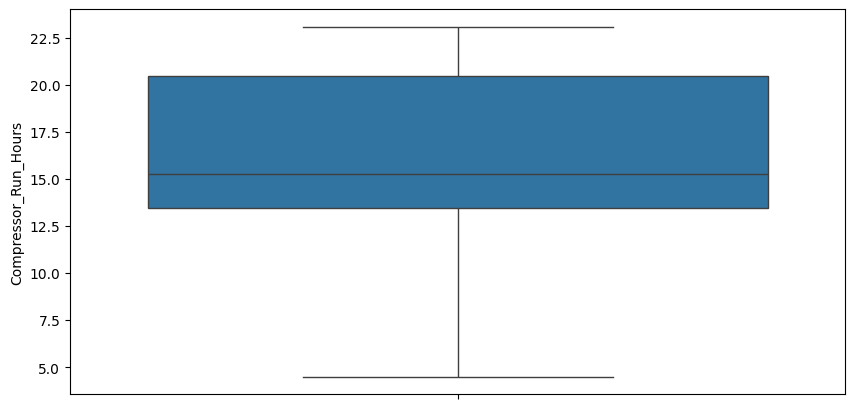

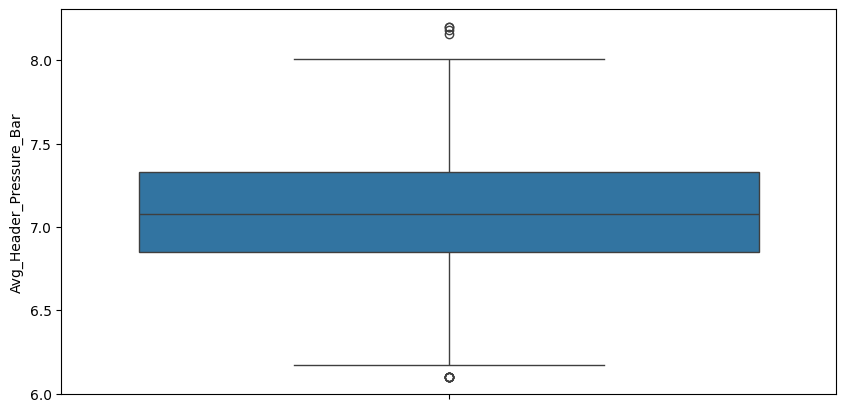

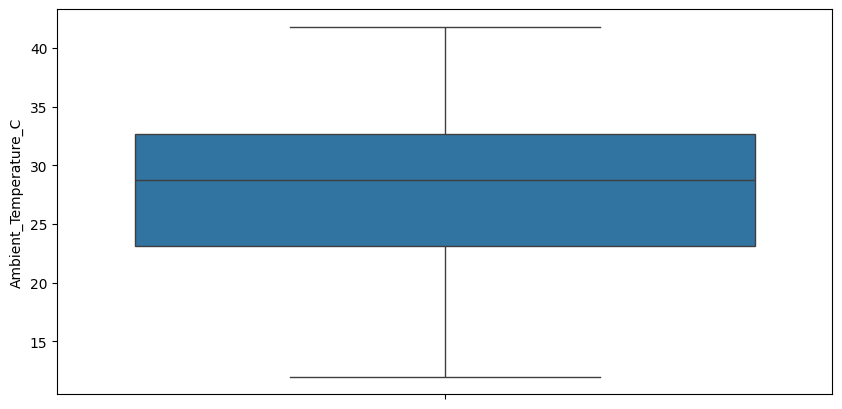

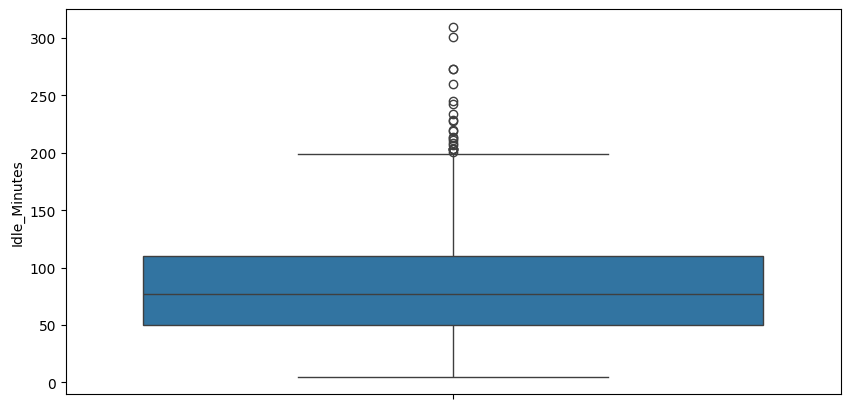

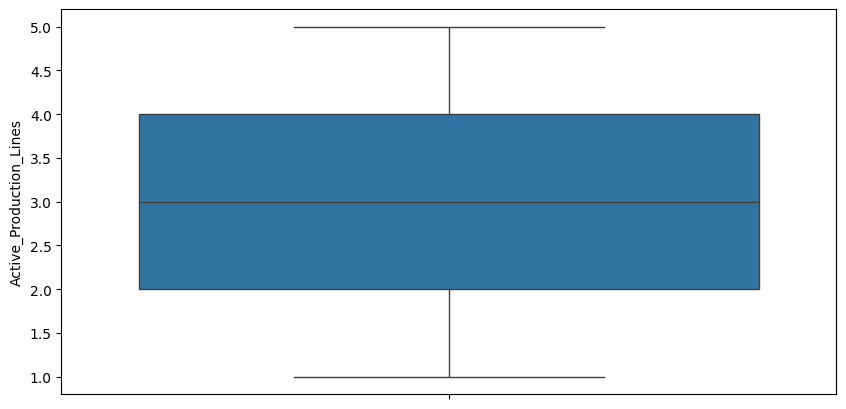

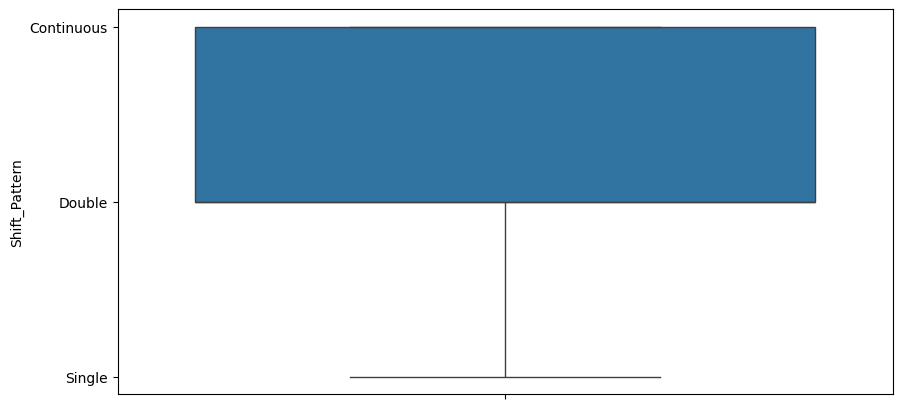

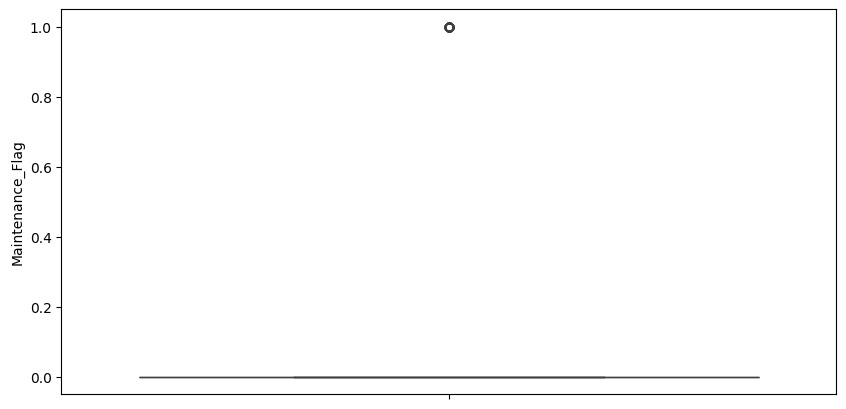

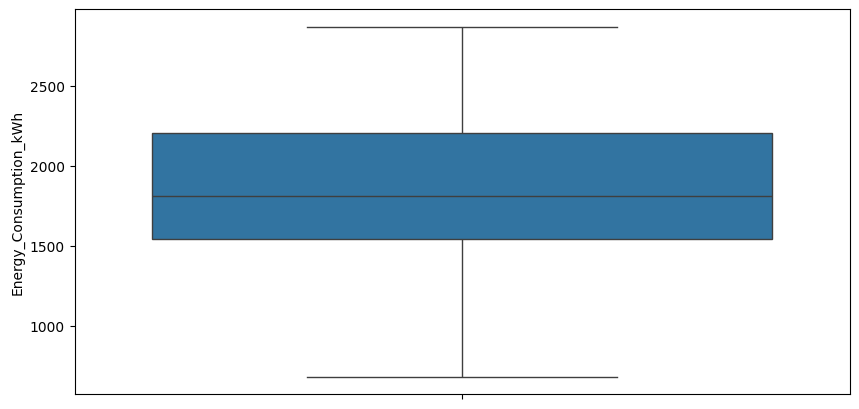

In [ ]:
for i in cols:
  plt.figure(figsize=(10,5))
  sns.boxplot(df[i])
  plt.show()

In [ ]:
outliers_col = ['Production_Units','Avg_Header_Pressure_Bar','Idle_Minutes']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Production_Units         900 non-null    int64  
 1   Compressor_Run_Hours     900 non-null    float64
 2   Avg_Header_Pressure_Bar  900 non-null    float64
 3   Ambient_Temperature_C    900 non-null    float64
 4   Idle_Minutes             900 non-null    int64  
 5   Active_Production_Lines  900 non-null    int64  
 6   Shift_Pattern            900 non-null    object 
 7   Maintenance_Flag         900 non-null    int64  
 8   Energy_Consumption_kWh   900 non-null    float64
dtypes: float64(4), int64(4), object(1)
memory usage: 63.4+ KB


In [ ]:
# for col in outliers_col:
#   q1 = df[col].quantile(0.25)
#   q3 = df[col].quantile(0.75)

#   iqr = q3-q1

#   upper_limit = q3 + 1.5*iqr
#   lower_limit = q1 - 1.5*iqr

#   df = df[(df[col] > lower_limit) & (df[col] < upper_limit)]

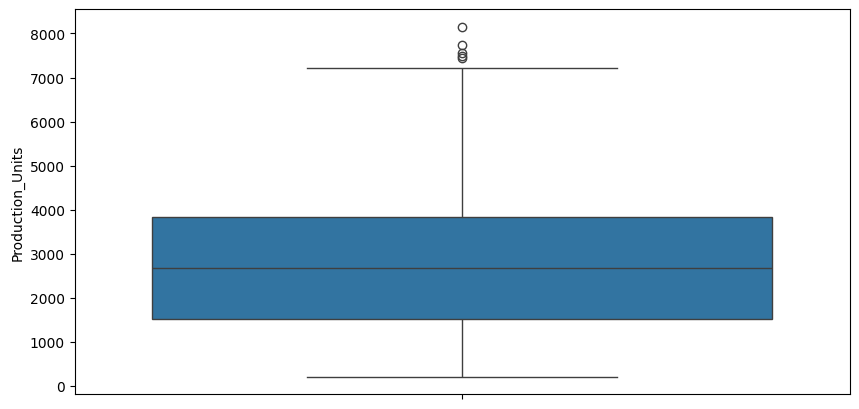

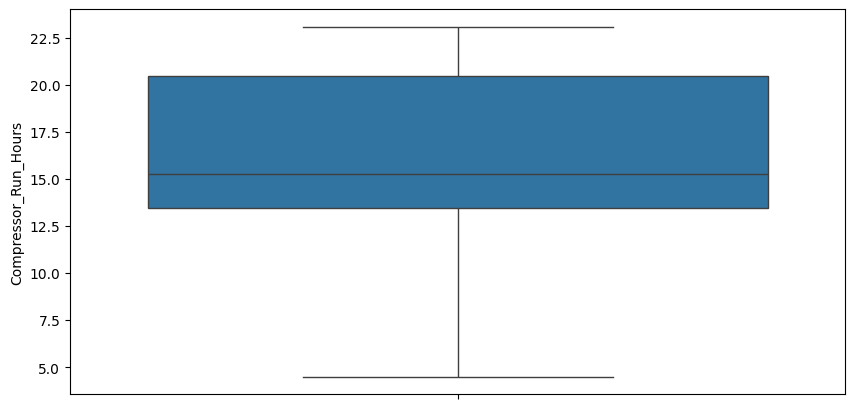

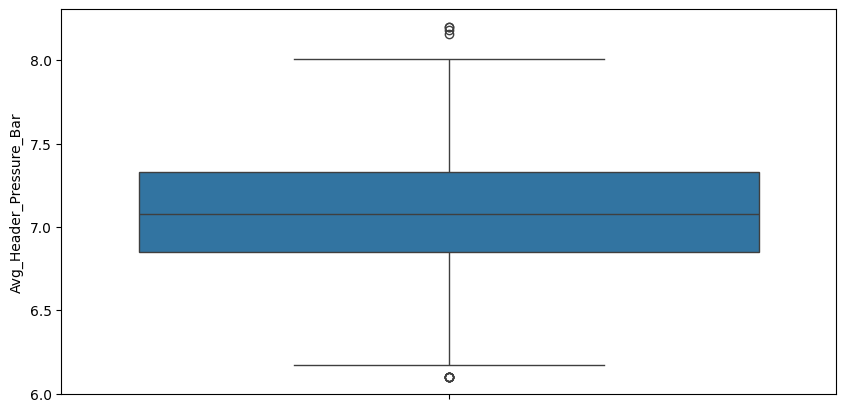

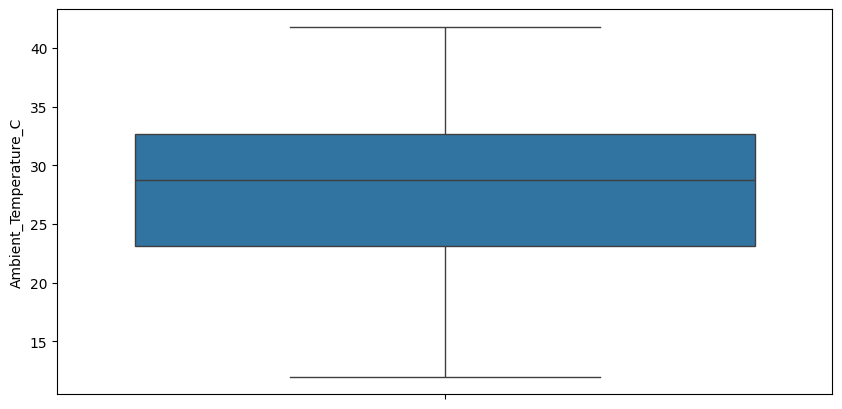

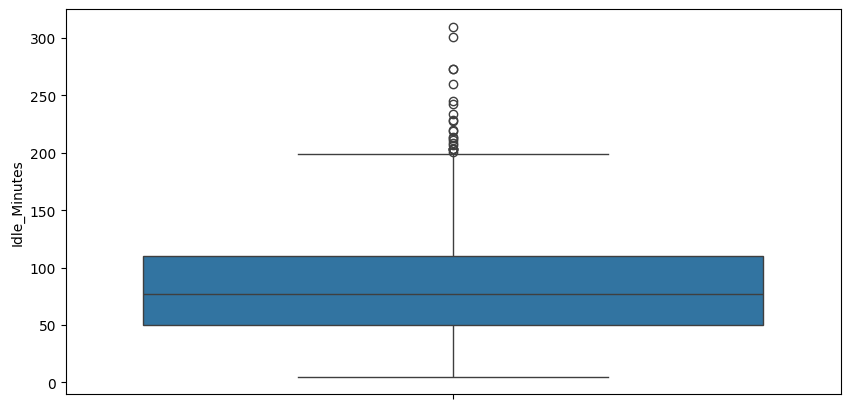

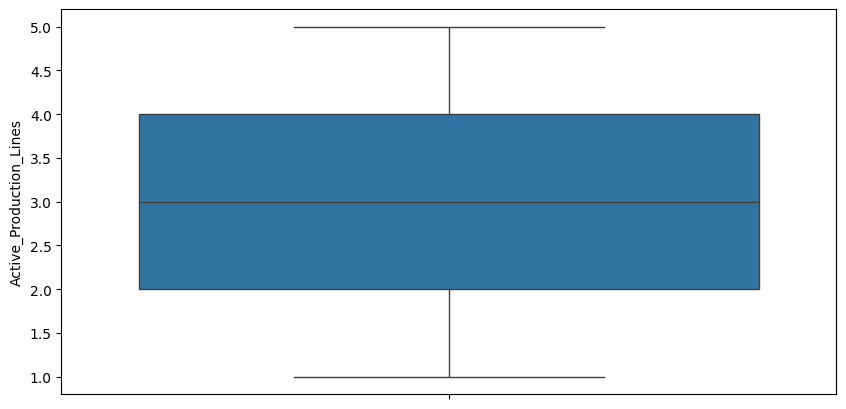

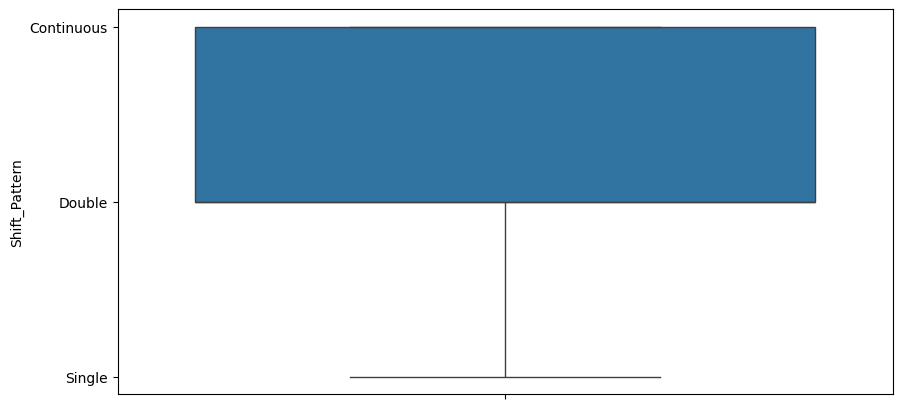

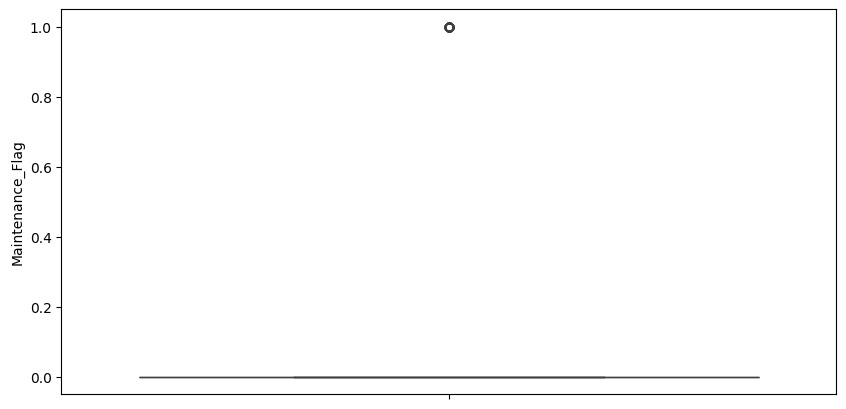

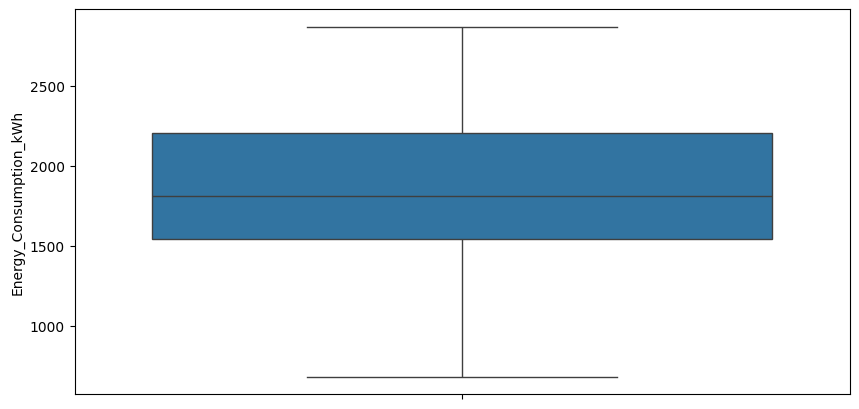

In [ ]:
for i in cols:
  plt.figure(figsize=(10,5))
  sns.boxplot(df[i])
  plt.show()

In [ ]:
df.head()

,Production_Units,Compressor_Run_Hours,Avg_Header_Pressure_Bar,Ambient_Temperature_C,Idle_Minutes,Active_Production_Lines,Shift_Pattern,Maintenance_Flag,Energy_Consumption_kWh
0,3824,20.44,7.30,24.3,36,3,Continuous,0,2196.2
1,4151,15.98,7.08,26.0,150,4,Double,0,2027.6
2,3770,20.57,6.89,26.1,103,3,Continuous,0,2212.5
3,5017,20.37,6.78,25.7,145,4,Continuous,0,2429.6
4,534,8.81,6.74,23.6,49,1,Single,0,883.4


In [ ]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded = encoder.fit_transform(df[['Shift_Pattern']])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(['Shift_Pattern']),
    index=df.index
)
df = pd.concat(
    [df.drop('Shift_Pattern', axis=1), encoded_df],
    axis=1
)

In [ ]:
df.head()

,Production_Units,Compressor_Run_Hours,Avg_Header_Pressure_Bar,Ambient_Temperature_C,Idle_Minutes,Active_Production_Lines,Maintenance_Flag,Energy_Consumption_kWh,Shift_Pattern_Continuous,Shift_Pattern_Double,Shift_Pattern_Single
0,3824,20.44,7.30,24.3,36,3,0,2196.2,1.0,0.0,0.0
1,4151,15.98,7.08,26.0,150,4,0,2027.6,0.0,1.0,0.0
2,3770,20.57,6.89,26.1,103,3,0,2212.5,1.0,0.0,0.0
3,5017,20.37,6.78,25.7,145,4,0,2429.6,1.0,0.0,0.0
4,534,8.81,6.74,23.6,49,1,0,883.4,0.0,0.0,1.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Production_Units          900 non-null    int64  
 1   Compressor_Run_Hours      900 non-null    float64
 2   Avg_Header_Pressure_Bar   900 non-null    float64
 3   Ambient_Temperature_C     900 non-null    float64
 4   Idle_Minutes              900 non-null    int64  
 5   Active_Production_Lines   900 non-null    int64  
 6   Maintenance_Flag          900 non-null    int64  
 7   Energy_Consumption_kWh    900 non-null    float64
 8   Shift_Pattern_Continuous  900 non-null    float64
 9   Shift_Pattern_Double      900 non-null    float64
 10  Shift_Pattern_Single      900 non-null    float64
dtypes: float64(7), int64(4)
memory usage: 77.5 KB


In [ ]:
x = df.drop(columns='Energy_Consumption_kWh')
y = df['Energy_Consumption_kWh']

In [ ]:
x

,Production_Units,Compressor_Run_Hours,Avg_Header_Pressure_Bar,Ambient_Temperature_C,Idle_Minutes,Active_Production_Lines,Maintenance_Flag,Shift_Pattern_Continuous,Shift_Pattern_Double,Shift_Pattern_Single
0,3824,20.44,7.30,24.3,36,3,0,1.0,0.0,0.0
1,4151,15.98,7.08,26.0,150,4,0,0.0,1.0,0.0
2,3770,20.57,6.89,26.1,103,3,0,1.0,0.0,0.0
3,5017,20.37,6.78,25.7,145,4,0,1.0,0.0,0.0
4,534,8.81,6.74,23.6,49,1,0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
895,3511,21.00,7.27,31.7,73,3,0,1.0,0.0,0.0
896,1866,17.04,8.18,31.2,120,2,0,0.0,1.0,0.0
897,2319,13.24,7.22,25.9,41,3,0,0.0,1.0,0.0
898,452,7.27,6.48,31.6,154,1,0,0.0,0.0,1.0


In [ ]:
y

,Energy_Consumption_kWh
0,2196.2
1,2027.6
2,2212.5
3,2429.6
4,883.4
...,...
895,2192.3
896,1959.9
897,1758.0
898,1031.5


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size = 0.8, random_state=42)

In [ ]:
model_lr = LinearRegression()
model_lr.fit(x_train, y_train)

LinearRegression()

In [ ]:
model_dt = DecisionTreeRegressor()
model_dt.fit(x_train, y_train)

DecisionTreeRegressor()

In [ ]:
model_rf = RandomForestRegressor()
model_rf.fit(x_train, y_train)

RandomForestRegressor()

In [ ]:
y_pred_lr = model_lr.predict(x_test)
y_pred_dt = model_dt.predict(x_test)
y_pred_rf = model_rf.predict(x_test)

In [ ]:
r2 = r2_score(y_test, y_pred_lr)
mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
print(f'linear regression: \nr2={r2} \nmae={mae}\nmse={mse}\nrmse={rmse}')

linear regression: 
r2=0.9803858617525544 
mae=57.773643427306446
mse=4974.1912364991
rmse=70.52794649285559


In [ ]:
print(f"The linear regression model is {r2_score(y_test, y_pred_lr) * 100}% accurate")

The linear regression model is 98.03858617525543% accurate


In [ ]:
r2 = r2_score(y_test, y_pred_dt)
mae = mean_absolute_error(y_test, y_pred_dt)
mse = mean_squared_error(y_test, y_pred_dt)
rmse = np.sqrt(mse)
print(f'decision tree: \nr2={r2} \nmae={mae}\nmse={mse}\nrmse={rmse}')

decision tree: 
r2=0.9350382470265952 
mae=99.53277777777774
mse=16474.452166666666
rmse=128.35284245651386


In [ ]:
print(f"The decision tree regression model is {r2_score(y_test, y_pred_lr) * 100}% accurate")

The decision tree regression model is 98.03858617525543% accurate


In [ ]:
r2 = r2_score(y_test, y_pred_rf)
mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
print(f'random forest regressino: \nr2={r2} \nmae={mae}\nmse={mse}\nrmse={rmse}')

random forest regressino: 
r2=0.9696789052416777 
mae=69.02565555555563
mse=7689.50039635557
rmse=87.68979642099512


In [ ]:
print(f"The random forest regression model is {r2_score(y_test, y_pred_lr) * 100}% accurate")

The random forest regression model is 98.03858617525543% accurate
